# EDA — Criteo (2018) — incrementalidad de publicidad display
**Proyecto Final · Lic. en Ciencia de Datos · Universidad CAECE**

13,98 millones de usuarios de tests de incrementalidad de Criteo: un 85 % fue expuesto a la publicidad del anunciante y un 15 % se mantuvo como control. Features anonimizadas (f0–f11) y dos outcomes: visita y conversión.

Notebook generado por `scripts/make_notebooks.py` a partir de `configs/criteo.yaml`. El análisis lo hace `uplift.eda` (genérico para cualquier dataset).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import numpy as np, pandas as pd
from IPython.display import Image, display
from uplift.dataset import load_config
pd.set_option("display.float_format", "{:.4f}".format)
cfg = load_config("criteo")
FIG = cfg.figures_dir
def show(name):
    p = FIG / f"{name}.png"
    if p.exists():
        display(Image(str(p)))
RUN = not (cfg.reports_dir / 'eda_summary.json').exists()

In [2]:
from uplift import eda
summary = eda.run(cfg) if RUN else json.load(open(cfg.reports_dir / 'eda_summary.json'))
pd.Series({k: v for k, v in summary['quality'].items() if not isinstance(v, dict)})

rows                  13979592
columns                     16
memory_mb             726.9000
missing_total                0
duplicated_rows          45136
duplicates_sampled        True
data_contract               ok
dtype: object

## 1. Diseño experimental y balance de covariables
En un experimento aleatorizado las covariables deben estar balanceadas entre brazos (|SMD| < 0,1).

,arm,label,n,share
0,Sin publicidad,control,2096937,0.1500
1,Publicidad,ads,11882655,0.8500


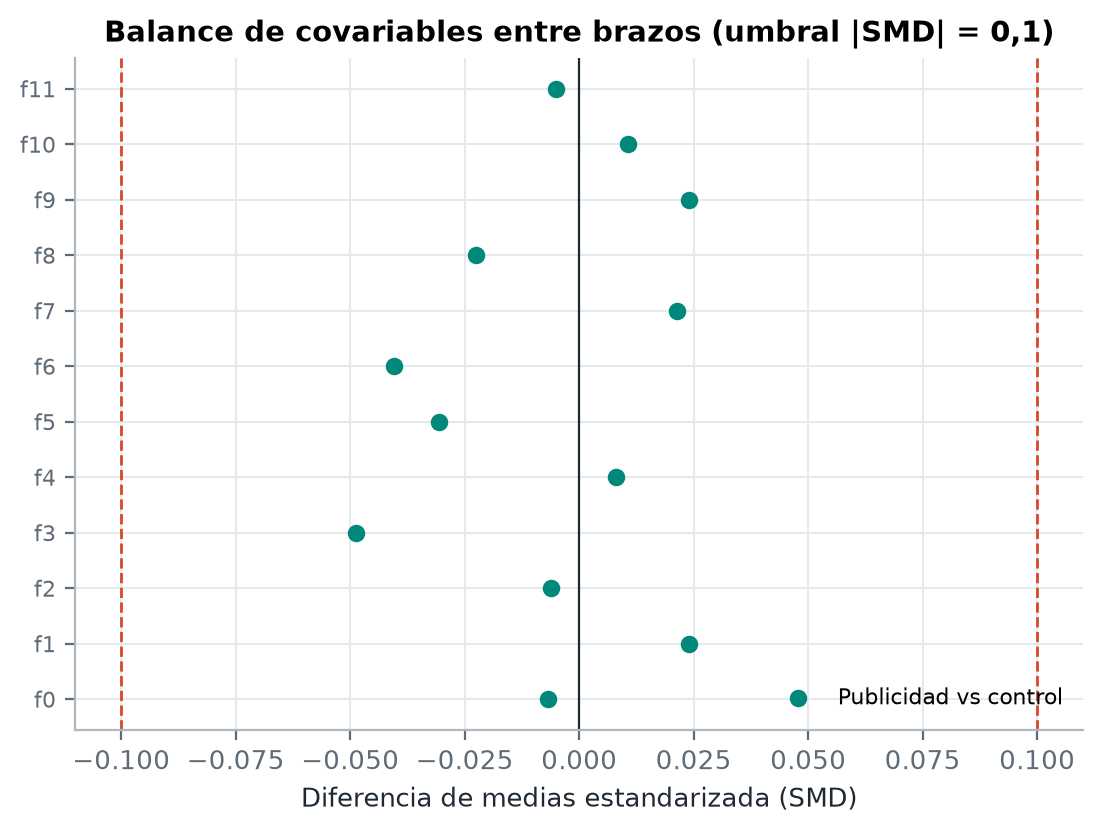

|SMD| máximo: 0.0488


In [3]:
display(pd.read_csv(cfg.tables_dir / 'eda_arm_counts.csv'))
show('eda_balance')
print('|SMD| máximo:', round(summary['max_abs_smd'], 4))

## 2. Efecto promedio de cada tratamiento (ATE)

,outcome,arm,n,mean,mean_lo,mean_hi,ate,ate_lo,ate_hi,relative_lift,p_value
0,visit,control,2096937,0.0382,0.0379,0.0385,NaN,NaN,NaN,NaN,NaN
1,visit,ads,11882655,0.0485,0.0484,0.0487,0.0103,0.0101,0.0106,0.2707,0.0000
2,conversion,control,2096937,0.0019,0.0019,0.0020,NaN,NaN,NaN,NaN,NaN
3,conversion,ads,11882655,0.0031,0.0031,0.0031,0.0012,0.0011,0.0012,0.5945,0.0000


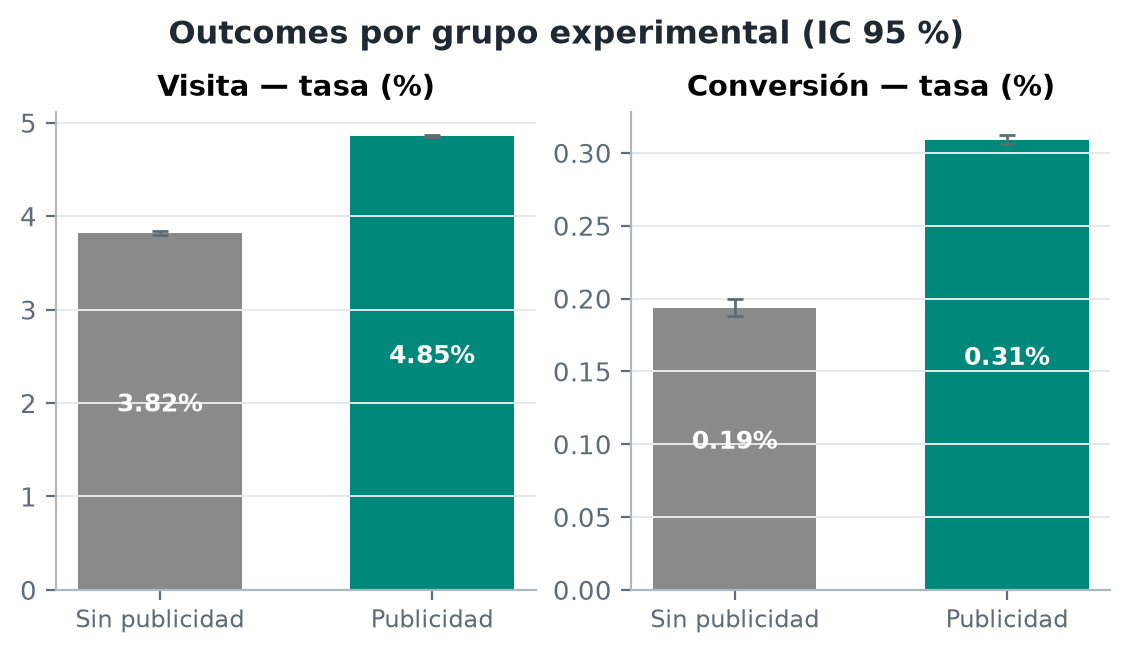

In [4]:
display(pd.read_csv(cfg.tables_dir / 'eda_ate.csv'))
show('eda_rates_by_group')

## 3. Distribuciones y correlaciones

,variable,mean,median,std,min,max,skewness,n_unique,zero_share,outliers_iqr
0,f0,19.6203,21.9234,5.3775,12.6164,26.7453,-0.2458,2181959,0.0000,0
1,f1,10.0700,10.0597,0.1048,10.0597,16.3442,13.9977,60,0.0000,171950
2,f2,8.4466,8.2144,0.2993,8.2144,9.0520,0.8064,808663,0.0000,0
3,f3,4.1789,4.6799,1.3366,-8.3984,4.6799,-3.1865,552,0.0000,2535597
4,f4,10.3388,10.2805,0.3433,10.2805,21.1235,8.8828,260,0.0000,606897
5,f5,4.0285,4.1155,0.4311,-9.0119,4.1155,-7.0858,132,0.0000,741443
6,f6,-4.1554,-2.4111,4.5779,-31.4298,0.2944,-1.1359,1645,0.0000,178726
7,f7,5.1018,4.8338,1.2052,4.8338,11.9984,4.5250,622143,0.0000,741443
8,f8,3.9336,3.9719,0.0567,3.6351,3.9719,-1.6056,3743,0.0000,920642
9,f9,16.0276,13.1901,7.0190,13.1901,75.2950,2.8227,1594,0.0000,2866257


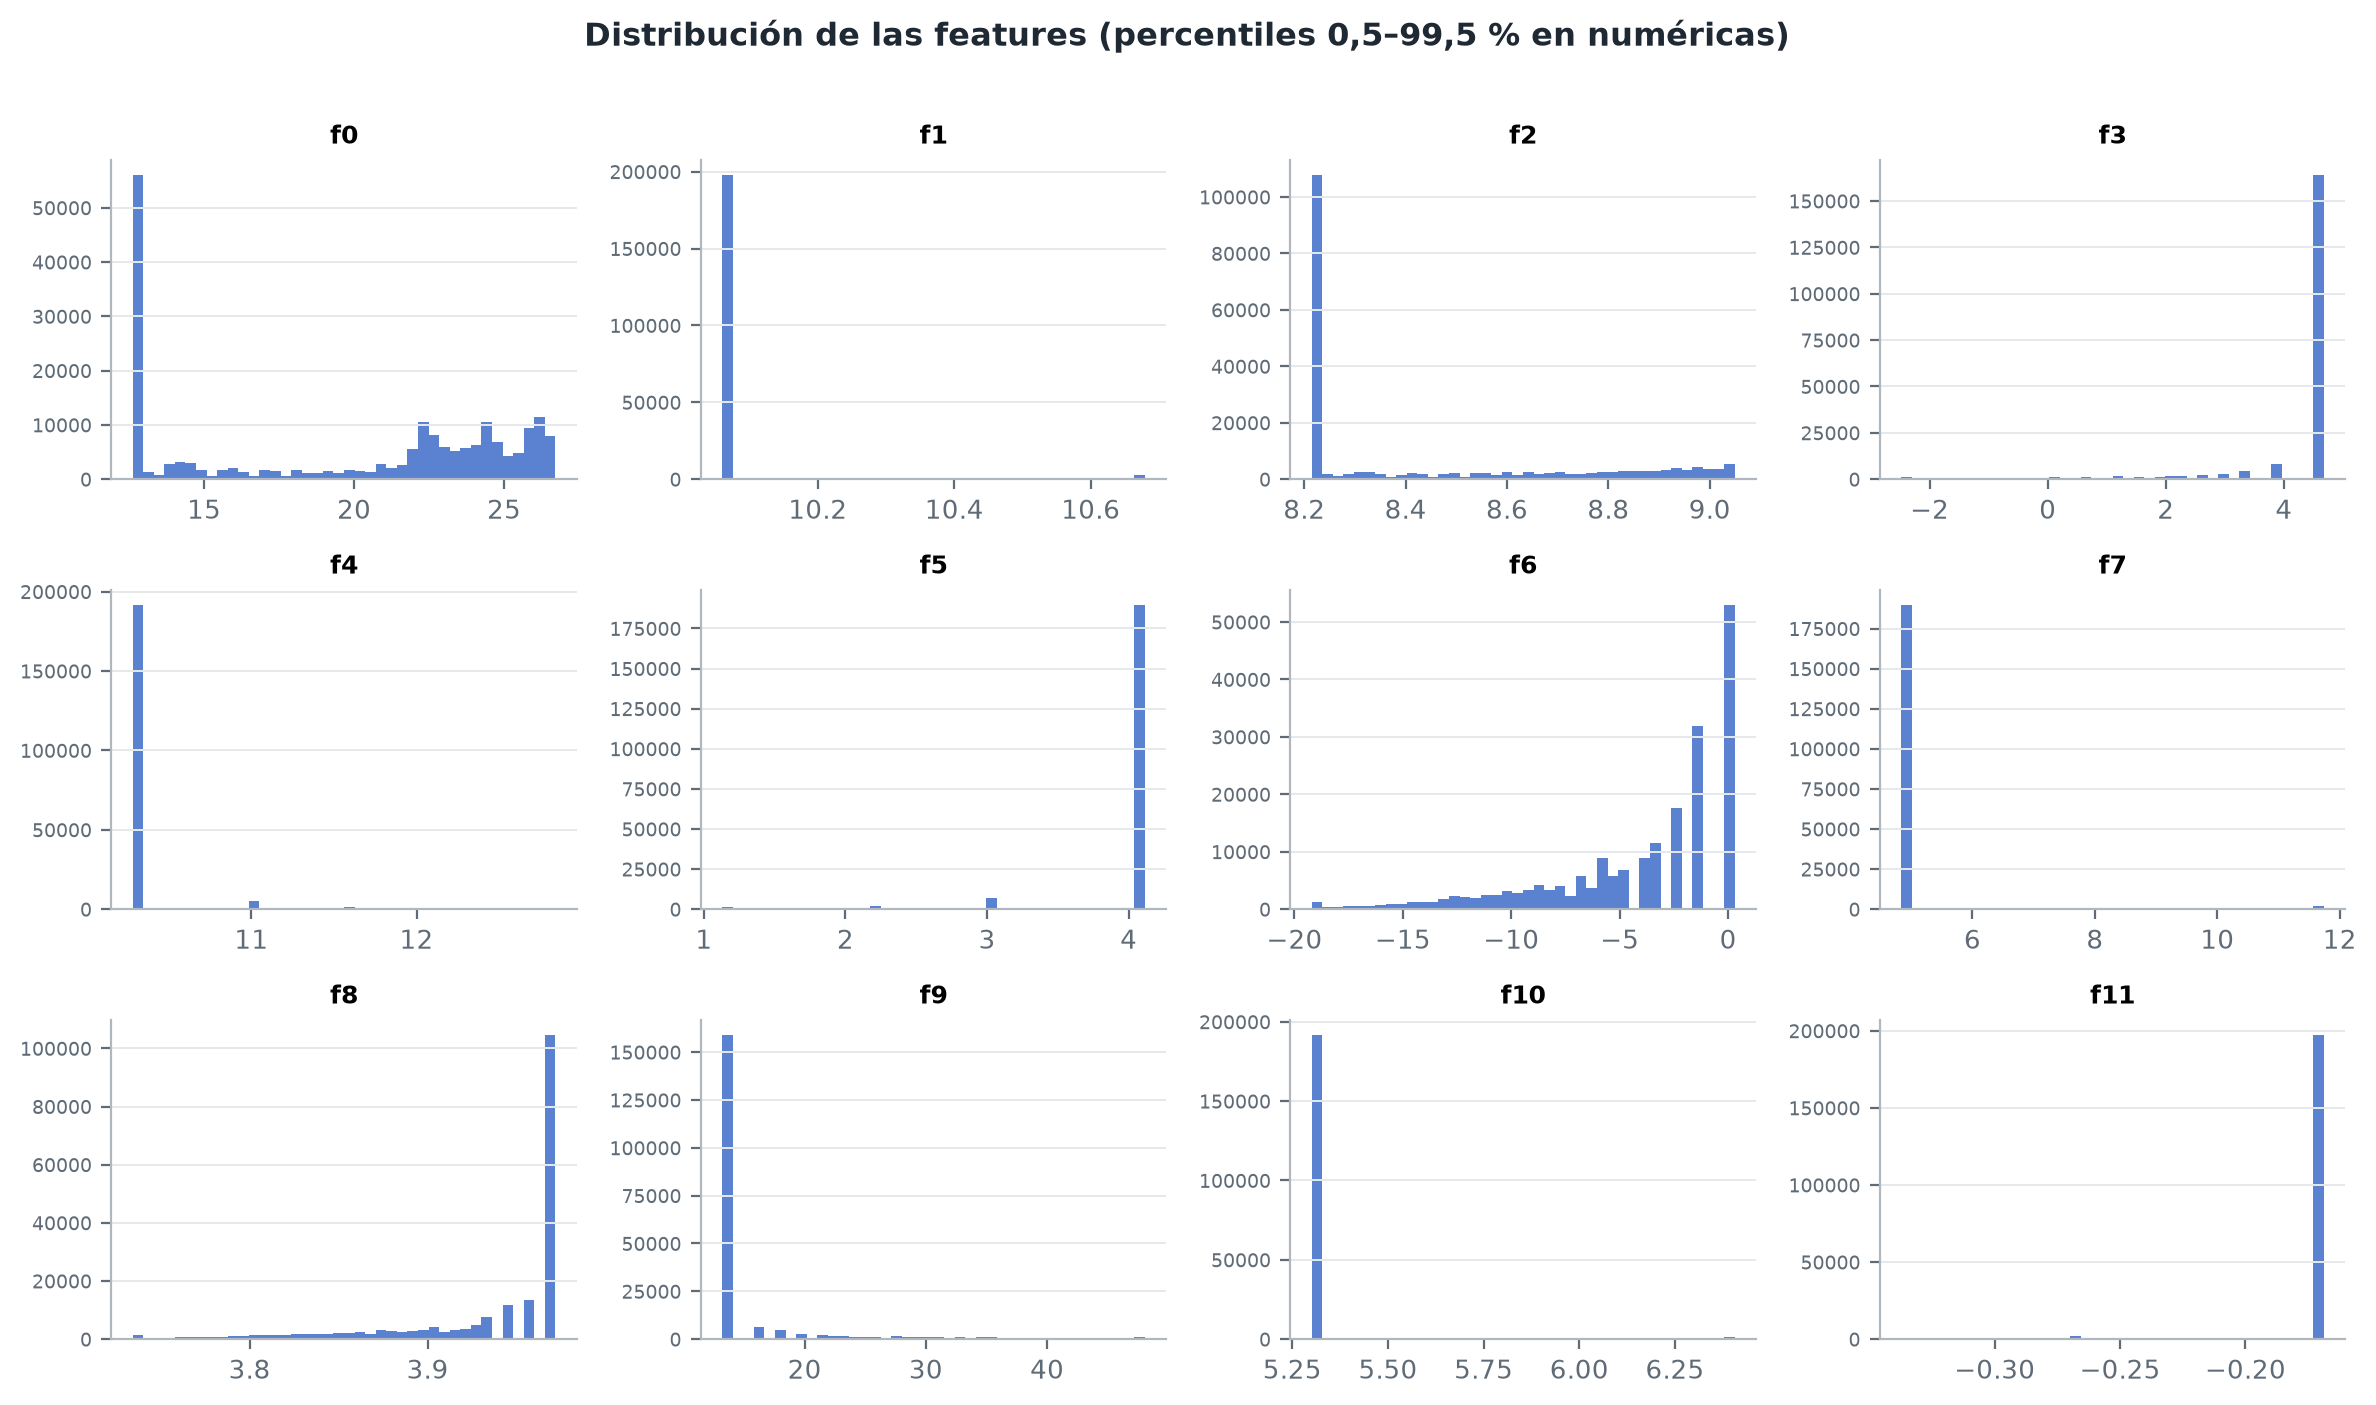

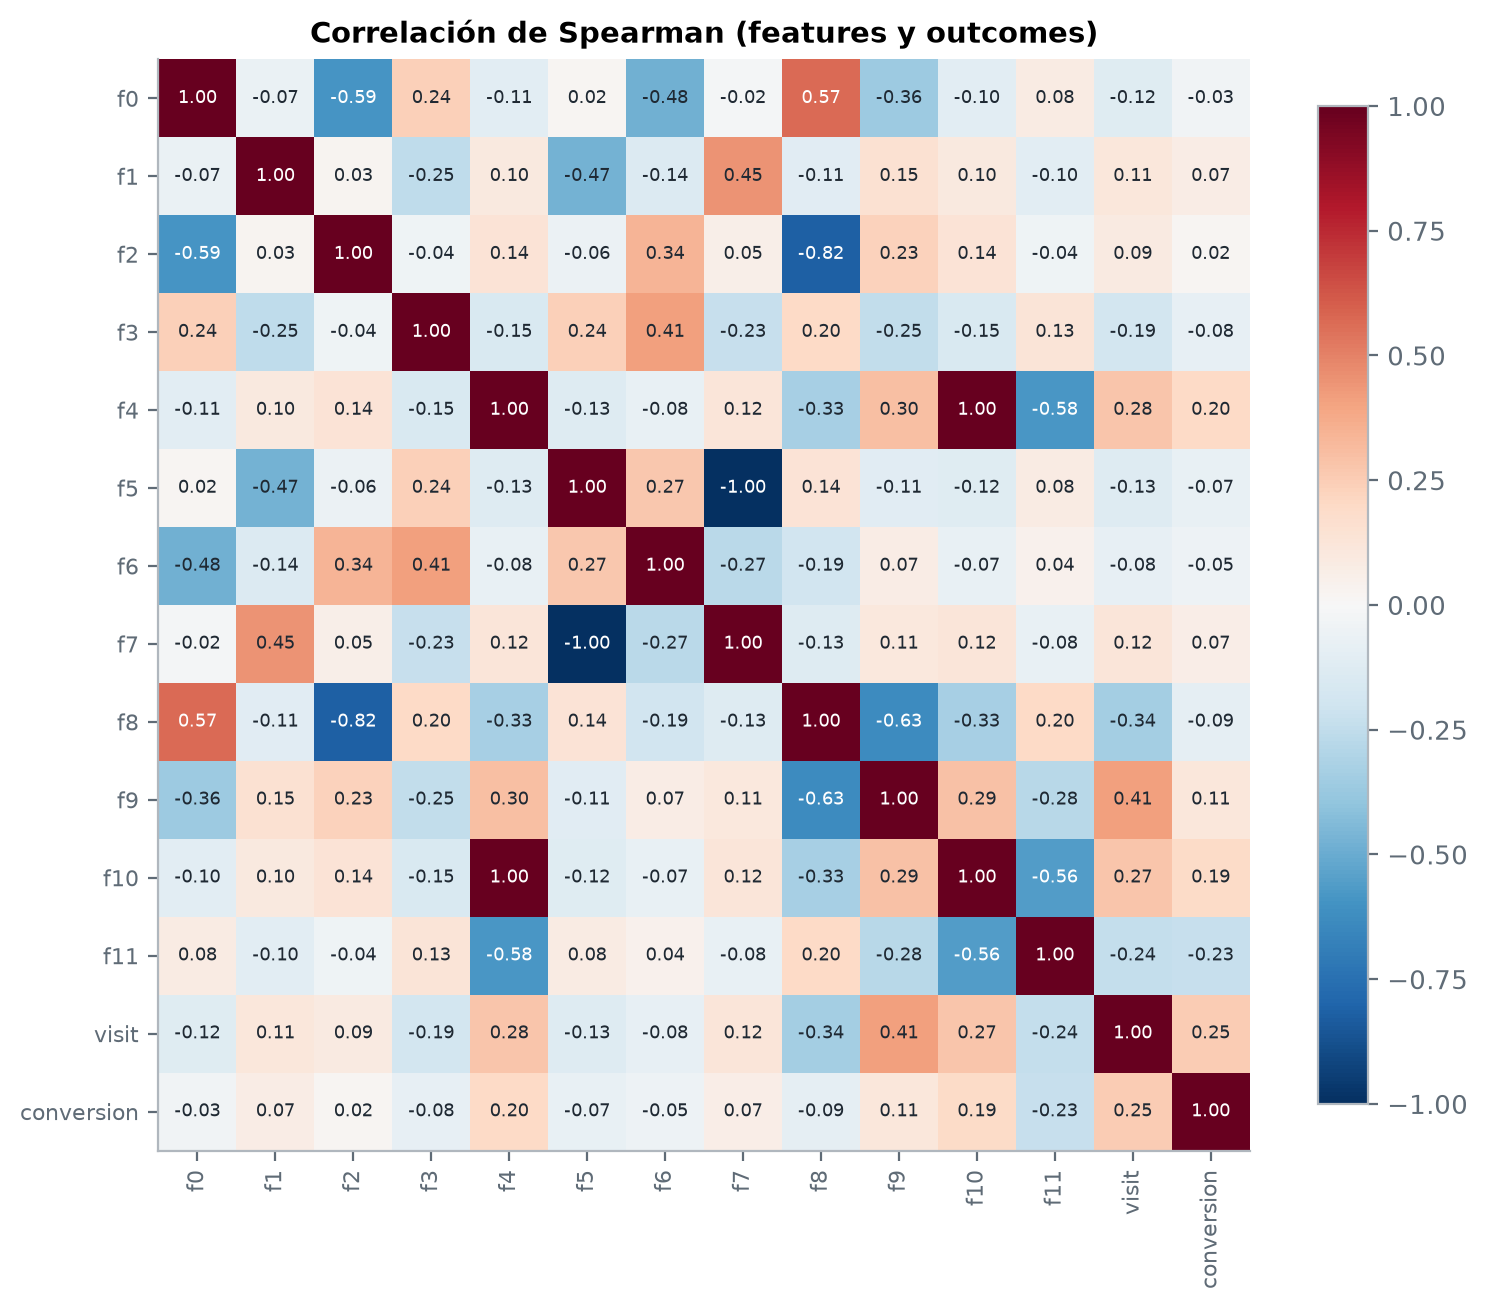

[{'a': 'f2', 'b': 'f8', 'rho': -0.8188168316444732},
 {'a': 'f4', 'b': 'f10', 'rho': 0.9992283386029877},
 {'a': 'f5', 'b': 'f7', 'rho': -0.998920130938696}]

In [5]:
display(pd.read_csv(cfg.tables_dir / 'eda_numeric_summary.csv'))
show('eda_distributions')
show('eda_outcome_distribution')
show('eda_correlation')
summary['strong_correlations']

## 4. Heterogeneidad del efecto
Si el efecto del tratamiento varía entre tramos de las features, el CATE individual es estimable (test Q de Cochran sobre los ATE por tramo).

,feature,arm,Q,df,p_value,ate_range
0,f3,ads,5918.1505,1,0.0000,0.0418
1,f6,ads,5862.7687,3,0.0000,0.0354
2,f8,ads,3512.9120,2,0.0000,0.0358
3,f0,ads,3326.4088,3,0.0000,0.0191
4,f9,ads,2623.7276,1,0.0000,0.0377
5,f5,ads,2286.9699,1,0.0000,0.0518
6,f7,ads,2286.9699,1,0.0000,0.0518
7,f2,ads,1545.3350,2,0.0000,0.0166
8,f1,ads,879.3968,1,0.0000,0.0851
9,f10,ads,489.1143,1,0.0000,0.0366


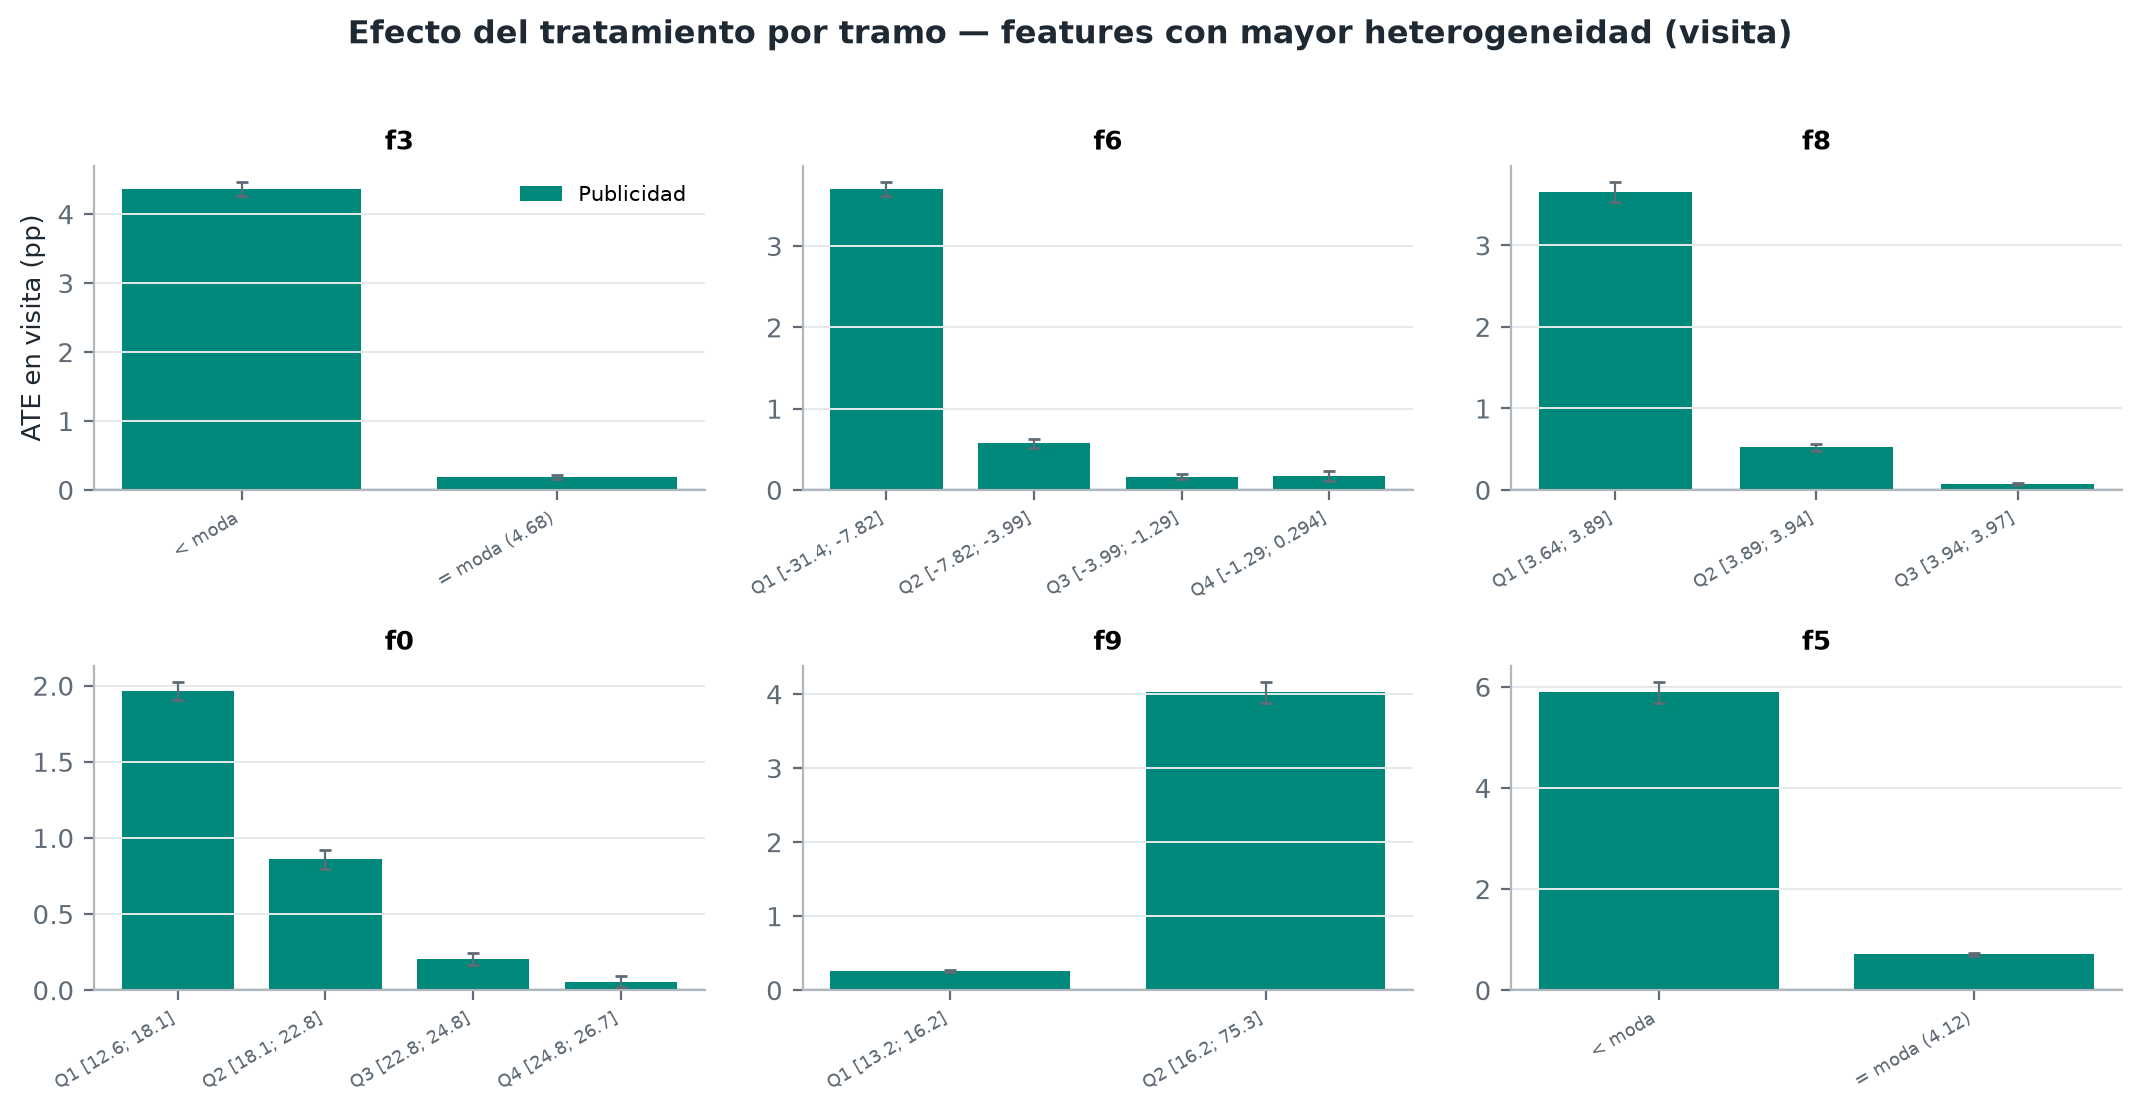

In [6]:
display(pd.read_csv(cfg.tables_dir / 'eda_heterogeneity_test_visit.csv').head(10))
show('eda_heterogeneity')
show('eda_heterogeneity_features')

## 5. Veredicto de viabilidad

In [7]:
display(pd.DataFrame(summary['viability']))
print('VIABLE' if summary['viable'] else 'REVISAR')

,criterio,aprobado,detalle
0,Sin valores faltantes,True,0 faltantes
1,Contrato de datos (dominios y restricciones ló...,True,ok
2,"Aleatorización válida (|SMD| < 0,1 en todas la...",True,|SMD| máx. = 0.049
3,"Efecto promedio significativo en visit (p < 0,05)",True,ads: +1.03 pp (p=0.0e+00)
4,Heterogeneidad del efecto detectable (Cochran ...,True,12 de 12 pares feature × tratamiento
5,Eventos suficientes por brazo (≥ 100 en cada o...,True,"mínimo = 4,063"


VIABLE
